# AgroPest-12 Part B: BYOL Pretraining for YOLOv12m

**Model:** YOLOv12m backbone, strict label-free BYOL pretraining  
**Dataset:** AgroPest-12-PartB-Safe SSL pool (9,180 images)  
**Platform:** Kaggle T4 x2  

This notebook pretrains a randomly initialized YOLOv12m backbone with BYOL. It reads only `ssl_pool/images`; labels, validation images, and test images are never accessed.

## Method and Protocol

BYOL (Bootstrap Your Own Latent) learns representations without negative pairs. Two independently augmented views of each image are processed by online and target branches. The online branch (encoder + projector + predictor) predicts the target branch's (encoder + projector) representation. The target branch is updated solely via exponential moving average (EMA) of the online weights, preventing representational collapse through asymmetry rather than contrastive negatives.

For a prediction \( p \) and a target projection \( z \), the loss per view pair is the normalized regression \( D(p, z) = 2 - 2\frac{p^T z}{\|p\|\|z\|} \). The symmetric loss averages both view directions. Only the online encoder transfers to the downstream detector.

The Part B partition policy forbids reading labels, validation images, or test images in this notebook. Diagnostics therefore use a fixed image-only sample from the SSL pool and do not make label-based claims.

In [1]:
# Install the current course SSL library and visualization dependency.
import subprocess, sys

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "ultralytics>=8.4.96", "scikit-learn", "seaborn"])
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "--no-deps", "git+https://github.com/rifat963/ssl-detection-lab.git@main"])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.1/46.1 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 87.8 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sklearn-compat 0.1.5 requires scikit-learn<1.9,>=1.2, but you have scikit-learn 1.9.0 which is incompatible.


0

In [2]:
# ============================================================
# CONFIG -- every value is fixed and viva-explainable
# ============================================================
from pathlib import Path

PARTB_ROOT = Path("/kaggle/input/datasets/sadikshahriar/agropest-12-partb-safe/AgroPest-12-PartB-Safe")
SSL_IMAGES = PARTB_ROOT / "ssl_pool" / "images"
OUTPUT_DIR = Path("/kaggle/working/partB_02a_byol_yolo12m")

SEED = 445                 # Shared Part B seed and fixed diagnostic sample.
YOLO_MODEL = "yolo12m.yaml" # Random architecture: no COCO-supervised initialization.
EPOCHS = 30               # Assignment B standard SSL pretraining budget.
IMAGE_SIZE = 224           # 88.9% of AgroPest boxes are large; preserves morphology while fitting a T4 contrastive batch.
PER_GPU_BATCH = 128        # Validated by warm-up run: 12.7 GiB/15 GB T4 at 224px. BYOL does 4 backbone passes but the resulting batch still fits safely.
WORKERS = 2                # Matches the Part A two-workers-per-GPU data-loading budget.
LEARNING_RATE = 3e-4       # Conservative AdamW rate inherited from the validated SimCLR AgroPest protocol.
MIN_LEARNING_RATE = 3e-6   # 100x lower cosine-decay floor for this 30-epoch SSL run.
WEIGHT_DECAY = 1e-4        # SSL regularization for the random encoder, projector, and predictor.
WARMUP_EPOCHS = 1          # Stabilizes random initialization without reducing the short SSL budget materially.
PROJECTION_DIM = 128       # Compact projection bottleneck; discarded alongside predictor before detector transfer.
HIDDEN_DIM = 512           # Matches the YOLOv12m pooled-feature scale without over-sizing the pretext-only MLPs.
MOMENTUM = 0.99            # Grill et al. (NeurIPS 2020) Table 5a: at 300 epochs tau_base=0.99 (72.5%) outruns 0.999 (69.8%). At 30 epochs (~2K steps), 0.996's 0.4%/step update is too slow for random init; 0.99 integrates 2.5x faster without entering the 0.9 collapse zone.
FINAL_MOMENTUM = 1.0       # Cosine schedule: tau=1-(1-tau_base)*(cos(pi*k/K)+1)/2 smoothly increases to 1.0 by the final epoch.
DIAGNOSTIC_IMAGES = 500    # Fixed image-only SSL-pool sample for t-SNE/retrieval.
RETRIEVAL_QUERIES = 4      # Four random panels, matching the SimCLR sanity-check style.
RETRIEVAL_NEIGHBORS = 5    # Assignment B requires query plus top-five cosine neighbours.

CLASS_NAMES = ["Ants", "Bees", "Beetles", "Caterpillars", "Earthworms", "Earwigs", "Grasshoppers", "Moths", "Slugs", "Snails", "Wasps", "Weevils"]
print(f"CONFIG loaded | BYOL | {YOLO_MODEL} | {EPOCHS} epochs | {PER_GPU_BATCH} images/GPU | {IMAGE_SIZE}px | momentum {MOMENTUM}→{FINAL_MOMENTUM}")

CONFIG loaded | BYOL | yolo12m.yaml | 30 epochs | 128 images/GPU | 224px | momentum 0.99→1.0


## Dataset-Specific CONFIG Rationale

This is not a copied football configuration. AgroPest images are native 640x640 and EDA found 88.9% large boxes, so 224px retains the dominant pest morphology for global SSL features while fitting a T4 BYOL batch of 128.

BYOL performs four backbone passes for every pair of views: two through the online encoder (with gradients) and two through the target encoder (EMA-updated, no gradients). A one-epoch Kaggle warm-up run confirmed that 128 images/GPU occupies 12.7 GiB of the 15 GB per T4, fitting safely. Unlike SimCLR, BYOL does not use contrastive negatives, so batch size does not affect the number of negatives — 128 is chosen purely for stable, low-variance gradient estimates at the largest size T4 memory allows.

The EMA momentum starts at 0.99 and follows a cosine schedule toward 1.0. This is a deliberate departure from the 1000-epoch canonical value of 0.996 for 30-epoch training. Grill et al. (NeurIPS 2020) Table 5a ablations at 300 epochs show τ_base = 0.99 achieves 72.5% vs. 69.8% for 0.999; at only ~2K total steps (30 epochs), 0.996’s 0.4%/step update is too slow for a randomly initialized encoder to build meaningful targets, while 0.99’s 1.0%/step tracks the rapidly evolving online encoder safely above the 0.9 collapse zone (68.4% in the ablation). AdamW with 3e-4, 1e-4 weight decay, one warmup epoch, cosine decay to 3e-6, AMP, and gradient clipping at 5.0 are the same stability controls proven by the SimCLR AgroPest run. The encoder begins from `yolo12m.yaml` (not COCO), so all learned features are attributable to the 9,180 label-free AgroPest images.

The same two-view augmentation family is used as SimCLR: random resized crops, horizontal flips, colour jitter (0.35), low hue jitter (0.06), grayscale probability 0.10, and Gaussian blur. BYOL is known to be more robust to weaker augmentation than SimCLR, so this moderate schedule should provide sufficient invariance while preserving pest-level semantics.

In [3]:
# ============================================================
# Environment and strict SSL-pool-only checks
# ============================================================
import json, random
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2
from tqdm.auto import tqdm
from ultralytics import YOLO

import ssldet
from ssldet import PretrainConfig, assert_supported_runtime, available_ssl_modules, launch_distributed_pretrain, transfer_ssl_backbone_to_yolo
from ssldet.backbones import YOLOBackboneEncoder
from ssldet.data import IMAGENET_MEAN, IMAGENET_STD, UnlabeledImageDataset, build_transform

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.set_float32_matmul_precision("high")
sns.set_theme(style="whitegrid")

assert SSL_IMAGES.is_dir(), f"Attach AgroPest-12-PartB-Safe. Missing: {SSL_IMAGES}"
assert not any(SSL_IMAGES.parent.rglob("*.txt")), "SSL pool must not contain label files."
runtime = assert_supported_runtime(require_cuda=True, minimum_gpus=2)
assert "byol" in available_ssl_modules()

IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png"}
ssl_paths = sorted(path for path in SSL_IMAGES.iterdir() if path.suffix.lower() in IMAGE_SUFFIXES)
assert len(ssl_paths) == 9180, f"Expected 9,180 SSL images, found {len(ssl_paths)}"

pd.Series({
    "ssl-detection-lab": ssldet.__version__, "PyTorch": torch.__version__,
    "Ultralytics": runtime["packages"]["ultralytics"]["installed"],
    "GPU count": runtime["cuda"]["device_count"],
    "GPUs": ", ".join(device["name"] for device in runtime["cuda"]["devices"]),
    "SSL images": len(ssl_paths), "label files visible": 0,
})

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


ssl-detection-lab                   0.8.0
PyTorch                      2.10.0+cu128
Ultralytics                       8.4.105
GPU count                               2
GPUs                   Tesla T4, Tesla T4
SSL images                           9180
label files visible                     0
dtype: object

## Augmentation Preview

BYOL uses the same two-view augmentation family as contrastive methods: random resized crops, horizontal flips, colour jitter, occasional grayscale conversion, and Gaussian blur. The online and target views should retain enough pest and scene content to be recognizable as the same source image while providing different viewpoints for the predictive objective.

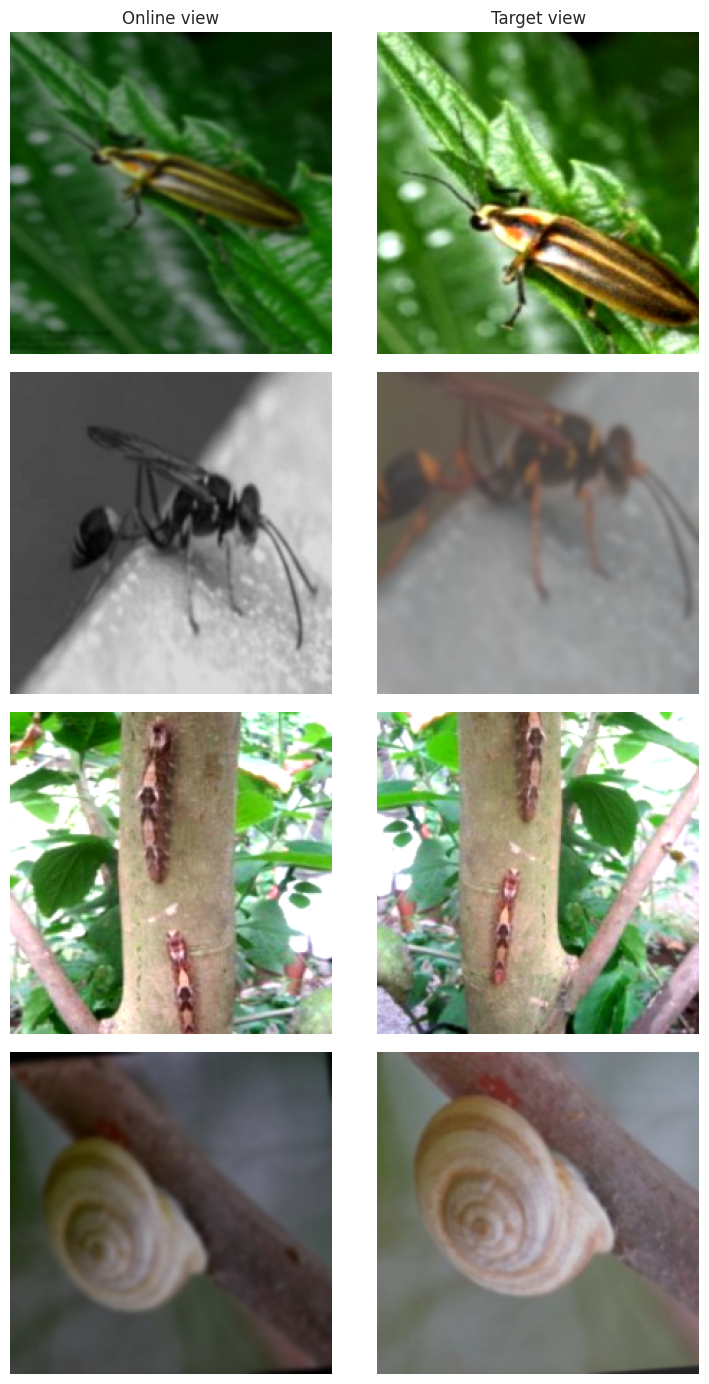

model initialization            random yolo12m.yaml (strict label-free SSL)
source images per DDP step                                              256
views per DDP step                                                      512
backbone passes per DDP step                                           1024
starting momentum                                                      0.99
final momentum                                                          1.0
AMP                                                                    True
dtype: object

In [4]:
config = PretrainConfig(
    method="byol", image_roots=[str(SSL_IMAGES)], output_dir=str(OUTPUT_DIR), yolo_model=YOLO_MODEL,
    epochs=EPOCHS, batch_size=PER_GPU_BATCH, image_size=IMAGE_SIZE, workers=WORKERS,
    seed=SEED, learning_rate=LEARNING_RATE, min_learning_rate=MIN_LEARNING_RATE,
    weight_decay=WEIGHT_DECAY, warmup_epochs=WARMUP_EPOCHS, grad_accum_steps=1,
    gradient_clip=5.0, amp=True, projection_dim=PROJECTION_DIM, hidden_dim=HIDDEN_DIM,
    momentum=MOMENTUM, final_momentum=FINAL_MOMENTUM, save_every=1,
).validate()

preview_dataset = UnlabeledImageDataset(ssl_paths, build_transform(config))
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
def denormalize(tensor):
    return (tensor.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0)

fig, axes = plt.subplots(4, 2, figsize=(8, 14))
for row, index in enumerate(random.Random(233).sample(range(len(preview_dataset)), 4)):
    view_a, view_b = preview_dataset[index]
    axes[row, 0].imshow(denormalize(view_a)); axes[row, 1].imshow(denormalize(view_b))
    axes[row, 0].set_ylabel(ssl_paths[index].name[:28], fontsize=8)
    for axis in axes[row]: axis.axis("off")
axes[0, 0].set_title("Online view"); axes[0, 1].set_title("Target view")
plt.tight_layout(); plt.show()

pd.Series({
    "model initialization": "random yolo12m.yaml (strict label-free SSL)",
    "source images per DDP step": PER_GPU_BATCH * runtime["cuda"]["device_count"],
    "views per DDP step": 2 * PER_GPU_BATCH * runtime["cuda"]["device_count"],
    "backbone passes per DDP step": 4 * PER_GPU_BATCH * runtime["cuda"]["device_count"],
    "starting momentum": MOMENTUM, "final momentum": FINAL_MOMENTUM,
    "AMP": config.amp,
})

## Distributed BYOL Pretraining

The library launches one process per T4 GPU. Each process maintains its own online network (encoder + projector + predictor), target network (encoder + projector, EMA-updated), and optimizer. The loss is the symmetric normalized regression between the online predictor output and the target projection. The target momentum follows a cosine schedule from 0.99 to 1.0 over the 30 epochs. See the CONFIG rationale above for the evidence-based choice of τ_base = 0.99 for short-run training.

BYOL is expected to be slower than SimCLR due to the four backbone passes per pair (two online + two target) and the additional predictor MLP. The loss is an SSL optimization signal, not detection mAP.

In [5]:
training_result = launch_distributed_pretrain(
    config, num_processes=runtime["cuda"]["device_count"],
    config_path=OUTPUT_DIR / "byol_config.yaml", check=True,
)
print(pd.Series({"completed": training_result.succeeded, "seconds": round(training_result.seconds, 1), "output": str(training_result.output_dir)}))

BYOL 01/30:   0%|          | 0/35 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/ssldet/trainer.py:203: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()
/usr/local/lib/python3.12/dist-packages/ssldet/trainer.py:203: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()
BYOL 0

Epoch 01 | loss=0.68028 | time=112.4s


BYOL 02/30: 100%|██████████| 35/35 [01:33<00:00,  2.67s/it, ema=0.99011, loss=0.0010, lr=2.99e-04]


Epoch 02 | loss=0.00106 | time=93.4s


BYOL 03/30: 100%|██████████| 35/35 [01:30<00:00,  2.60s/it, ema=0.99024, loss=0.0001, lr=2.97e-04]


...

Epoch 29 | loss=0.02246 | time=90.6s


BYOL 30/30: 100%|██████████| 35/35 [01:29<00:00,  2.56s/it, ema=1.00000, loss=0.0221, lr=3.00e-06]


Epoch 30 | loss=0.02207 | time=89.6s


/usr/local/lib/python3.12/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)


{
  "output_dir": "/kaggle/working/partB_02a_byol_yolo12m",
  "yolo_checkpoint": "/kaggle/working/partB_02a_byol_yolo12m/byol_pretrained_yolo12m.pt",
  "ssl_checkpoint": "/kaggle/working/partB_02a_byol_yolo12m/last_ssl.pt",
  "history_csv": "/kaggle/working/partB_02a_byol_yolo12m/history.csv",
  "manifest_json": "/kaggle/working/partB_02a_byol_yolo12m/run_manifest.json"
}
{
  "output_dir": "/kaggle/working/partB_02a_byol_yolo12m",
  "yolo_checkpoint": "/kaggle/working/partB_02a_byol_yolo12m/byol_pretrained_yolo12m.pt",
  "ssl_checkpoint": "/kaggle/working/partB_02a_byol_yolo12m/last_ssl.pt",
  "history_csv": "/kaggle/working/partB_02a_byol_yolo12m/history.csv",
  "manifest_json": "/kaggle/working/partB_02a_byol_yolo12m/run_manifest.json"
}
completed                                      True
seconds                                      2803.1
output       /kaggle/working/partB_02a_byol_yolo12m
dtype: object


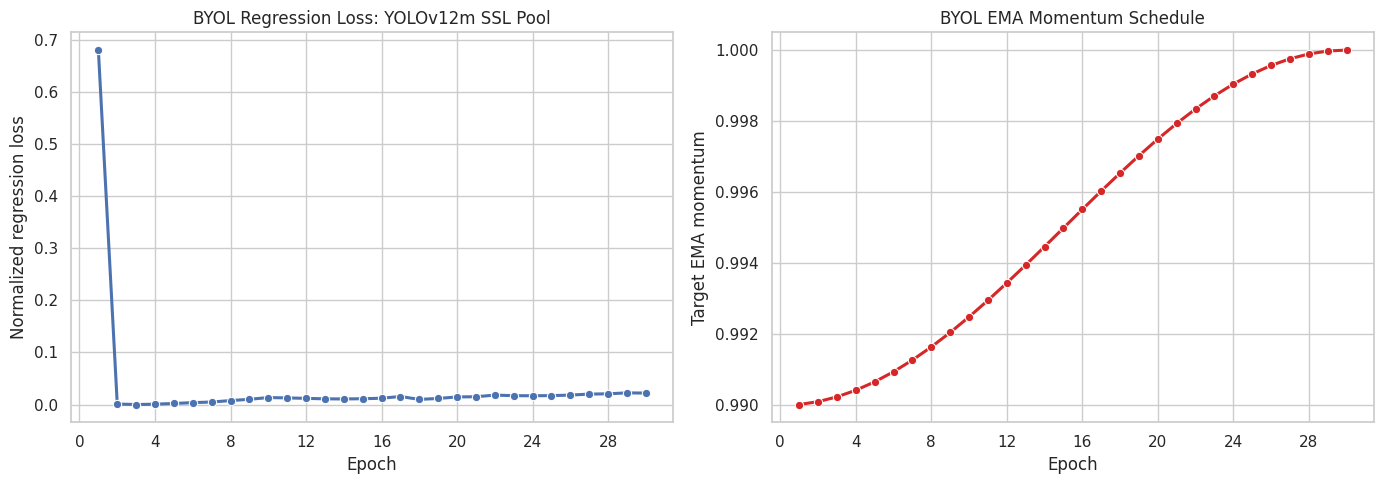

best SSL loss                                                              0.000112
best SSL checkpoint               /kaggle/working/partB_02a_byol_yolo12m/best_ss...
latest resumable checkpoint       /kaggle/working/partB_02a_byol_yolo12m/last_ss...
detector-compatible checkpoint    /kaggle/working/partB_02a_byol_yolo12m/byol_be...
backbone key coverage                                                        100.0%
transfer report                   /kaggle/working/partB_02a_byol_yolo12m/byol_be...
dtype: object

In [6]:
# ============================================================
# Loss curve, momentum schedule, and checkpoint handoff
# ============================================================
history = pd.read_csv(OUTPUT_DIR / "history.csv")
manifest = json.loads((OUTPUT_DIR / "run_manifest.json").read_text(encoding="utf-8"))
LAST_SSL_CHECKPOINT = Path(manifest["outputs"]["ssl_checkpoint"])
SSL_CHECKPOINT = OUTPUT_DIR / "best_ssl.pt"
assert SSL_CHECKPOINT.is_file(), f"Missing lowest-loss checkpoint: {SSL_CHECKPOINT}"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.lineplot(data=history, x="epoch", y="loss", marker="o", linewidth=2.2, ax=axes[0])
axes[0].set(title="BYOL Regression Loss: YOLOv12m SSL Pool", xlabel="Epoch", ylabel="Normalized regression loss")
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
sns.lineplot(data=history, x="epoch", y="ema_momentum", marker="o", linewidth=2.2, color="#d62728", ax=axes[1])
axes[1].set(title="BYOL EMA Momentum Schedule", xlabel="Epoch", ylabel="Target EMA momentum")
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "byol_loss_and_momentum.png", dpi=160); plt.show()

TRANSFERRED_YOLO = OUTPUT_DIR / "byol_best_backbone_yolo12m.pt"
transfer = transfer_ssl_backbone_to_yolo(
    SSL_CHECKPOINT, TRANSFERRED_YOLO, yolo_model=YOLO_MODEL, minimum_coverage=0.95,
)
pd.Series({
    "best SSL loss": manifest["best_loss"], "best SSL checkpoint": str(SSL_CHECKPOINT),
    "latest resumable checkpoint": str(LAST_SSL_CHECKPOINT),
    "detector-compatible checkpoint": str(TRANSFERRED_YOLO),
    "backbone key coverage": f"{transfer.coverage:.1%}", "transfer report": str(transfer.report_json),
})

## Representation Diagnostics And Retrieval Sanity Check

These diagnostics use a fixed, image-only sample from `ssl_pool/images`, not validation or test data. t-SNE preserves local neighborhoods only and is exploratory. The retrieval panel is the qualitative sanity check: a query should retrieve images with related pest appearance, scene structure, colour, or background rather than arbitrary images.

For BYOL specifically, a collapsed representation (all features identical) would produce a single-point t-SNE and random cosine neighbours. The normalized feature norm near 1.0 and non-zero per-dimension standard deviation are additional anti-collapse checks. Detection usefulness is established later by the downstream 20%-label experiment.

In [7]:
diagnostic_paths = sorted(random.Random(SEED).sample(ssl_paths, min(DIAGNOSTIC_IMAGES, len(ssl_paths))))
evaluation_transform = v2.Compose([
    v2.Resize(IMAGE_SIZE + 32, antialias=True), v2.CenterCrop(IMAGE_SIZE), v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True), v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
class SSLFeatureDataset(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            return evaluation_transform(image.convert("RGB")), self.paths[index].name

feature_loader = DataLoader(SSLFeatureDataset(diagnostic_paths), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
device = torch.device("cuda:0")  # Diagnostics are single-process inference after DDP training has exited.
diagnostic_detector = YOLO(str(TRANSFERRED_YOLO))
diagnostic_encoder = YOLOBackboneEncoder(diagnostic_detector.model).to(device).eval()
features, names = [], []
with torch.inference_mode():
    for images, batch_names in tqdm(feature_loader, desc="Extracting SSL-pool features"):
        features.append(F.normalize(diagnostic_encoder(images.to(device, non_blocking=True)), dim=1).cpu())
        names.extend(batch_names)
feature_matrix = torch.cat(features)
assert torch.isfinite(feature_matrix).all()
pd.Series({
    "diagnostic images": len(names), "feature dimensions": feature_matrix.shape[1],
    "mean L2 norm": feature_matrix.norm(dim=1).mean().item(),
    "mean feature std": feature_matrix.std(dim=0).mean().item(),
})

Extracting SSL-pool features:   0%|          | 0/8 [00:00<?, ?it/s]

diagnostic images     500.000000
feature dimensions    512.000000
mean L2 norm            1.000000
mean feature std        0.018106
dtype: float64

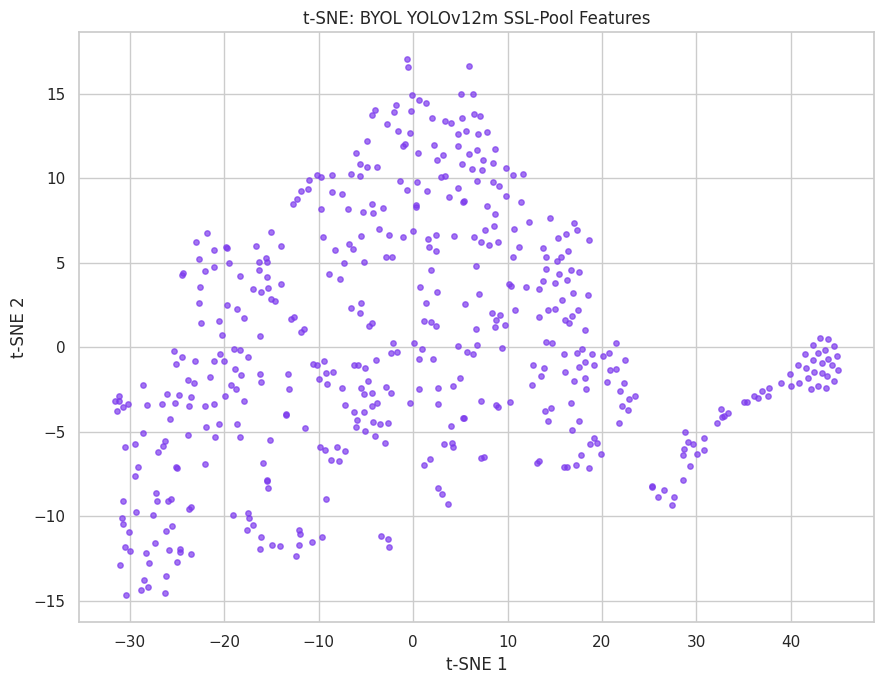

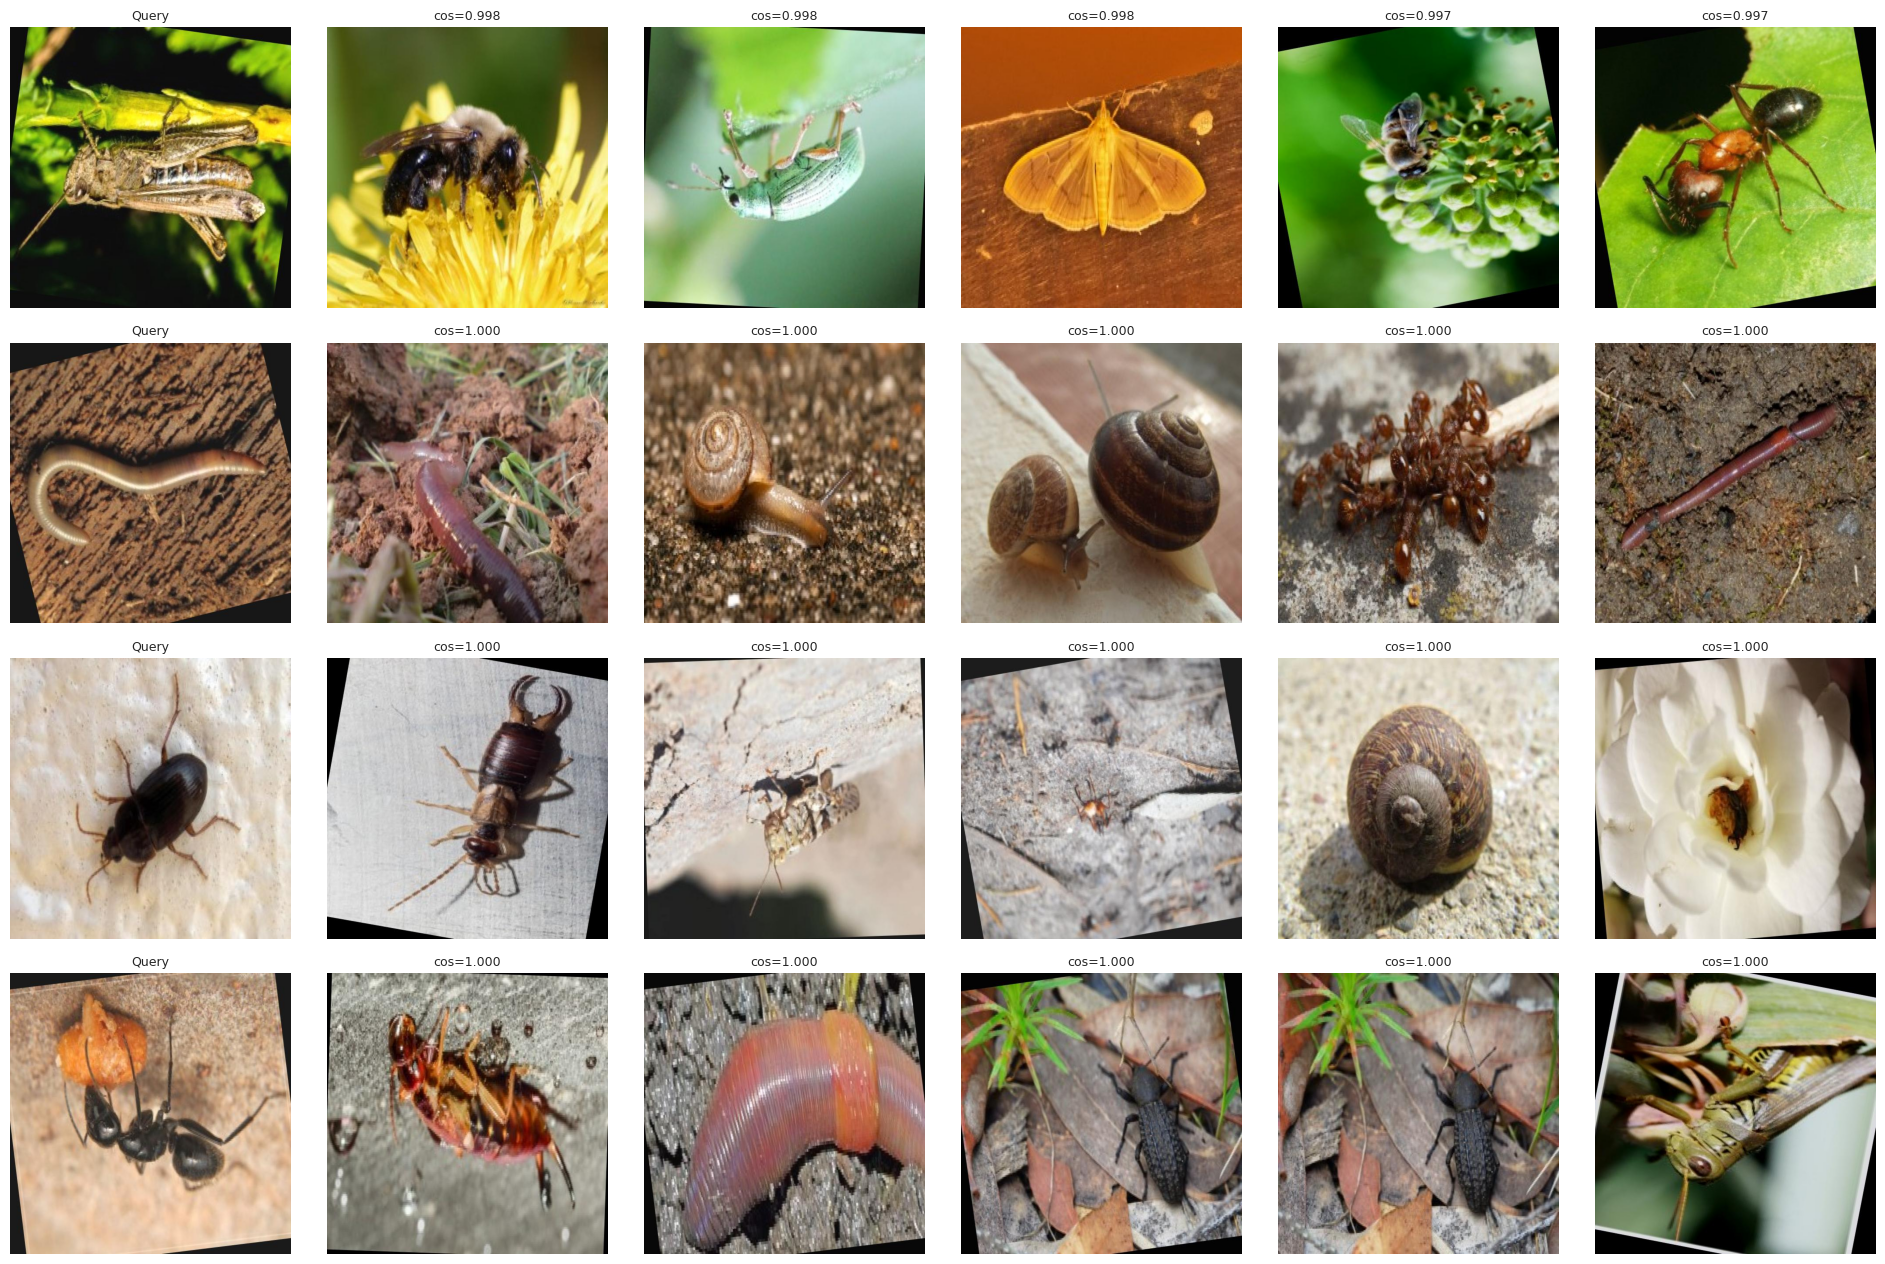

Interpretation to complete after execution: describe whether retrieved images share meaningful visual structure with the query, and defer all detection-performance claims to Notebook 02b.


In [8]:
perplexity = min(30.0, max(5.0, (len(feature_matrix) - 1) / 3))
coordinates = TSNE(n_components=2, perplexity=perplexity, learning_rate="auto", init="pca", max_iter=1000, random_state=SEED).fit_transform(feature_matrix.numpy())
fig, axis = plt.subplots(figsize=(9, 7))
axis.scatter(coordinates[:, 0], coordinates[:, 1], s=15, alpha=0.7, color="#7c3aed")
axis.set(title="t-SNE: BYOL YOLOv12m SSL-Pool Features", xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "byol_tsne_ssl_pool.png", dpi=160); plt.show()
pd.DataFrame({"filename": names, "tsne_1": coordinates[:, 0], "tsne_2": coordinates[:, 1]}).to_csv(OUTPUT_DIR / "ssl_pool_embeddings_tsne.csv", index=False)

query_indices = random.Random(SEED).sample(range(len(diagnostic_paths)), RETRIEVAL_QUERIES)
fig, axes = plt.subplots(RETRIEVAL_QUERIES, RETRIEVAL_NEIGHBORS + 1, figsize=(3.2 * (RETRIEVAL_NEIGHBORS + 1), 3.2 * RETRIEVAL_QUERIES))
retrieval_rows = []
for row, query_index in enumerate(query_indices):
    similarities = feature_matrix @ feature_matrix[query_index]
    neighbor_indices = [index for index in torch.topk(similarities, k=RETRIEVAL_NEIGHBORS + 1).indices.tolist() if index != query_index][:RETRIEVAL_NEIGHBORS]
    display_indices = [query_index] + neighbor_indices
    for column, index in enumerate(display_indices):
        with Image.open(diagnostic_paths[index]) as image: axes[row, column].imshow(image.convert("RGB"))
        title = "Query" if column == 0 else f"cos={similarities[index]:.3f}"
        axes[row, column].set_title(title, fontsize=9); axes[row, column].axis("off")
        retrieval_rows.append({"query": diagnostic_paths[query_index].name, "rank": column, "match": diagnostic_paths[index].name, "cosine_similarity": float(similarities[index])})
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "byol_nearest_neighbors.png", dpi=160); plt.show()
pd.DataFrame(retrieval_rows).to_csv(OUTPUT_DIR / "byol_nearest_neighbors.csv", index=False)

print("Interpretation to complete after execution: describe whether retrieved images share meaningful visual structure with the query, and defer all detection-performance claims to Notebook 02b.")

## Checkpoint Publication And Viva Notes

Publish the complete `/kaggle/working/partB_02a_byol_yolo12m/` directory as a public Kaggle dataset. Notebook `02b` must attach it and use `best_ssl.pt` with its transfer report.

- **Online network:** encoder + projector + predictor. Trained by gradient descent. Only the encoder transfers to detection.
- **Target network:** encoder + projector. Updated solely by EMA of the online weights: \(\xi \leftarrow m\xi + (1-m)\theta\), where \(m\) follows the cosine schedule from 0.99 toward 1.0 (Grill et al. Table 5a: τ_base=0.99 optimal at 300 epochs; 0.996 too slow for our ~2K short-run steps).
- **Predictor:** an asymmetric MLP on the online side that breaks symmetry and prevents representational collapse without negative pairs.
- **Loss:** \(L = \frac{1}{2}(D(p_1, \operatorname{sg}(z_2)) + D(p_2, \operatorname{sg}(z_1)))\) where \(D(p,z) = 2 - 2\frac{p^T z}{\|p\|\|z\|}\) and \(\operatorname{sg}\) stops gradients.
- The projection head and predictor are discarded after pretraining; only the backbone transfers.
- BYOL's compute cost is higher than SimCLR (4 backbone passes vs 2 per pair), but it does not require a large batch since it has no contrastive negatives.
- A non-zero mean feature standard deviation and distinct t-SNE clusters are basic anti-collapse signs. The canonical BYOL collapse detection is to check that the normalized prediction and target are not identical — if \(D(p, \operatorname{sg}(z))\) approaches zero but features collapse, the predictor may be learning to cancel the encoder.